# EDA: SAP Bikes Sales

SAP's Bikes Sales sample data: nine CSV files describing a bicycle company's orders, products, partners and employees.
The goal is to find what `preprocessing.py` has to fix before an AI agent can look up and change this data.

## 1. Load and preview

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%config InlineBackend.figure_format = "retina"
pd.set_option("display.max_columns", None, "display.max_colwidth", None)
sns.set_theme(style="whitegrid", rc={"axes.grid.axis": "y"})

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#c3c2b7"
RAW_DIR = Path("../data/raw")

In [2]:
def load(name, encoding="utf-8-sig"):
    # Read everything as text so that zero-padded IDs such as 0500000000 stay intact.
    return pd.read_csv(RAW_DIR / f"{name}.csv", dtype=str, keep_default_na=False, encoding=encoding)


addresses = load("Addresses")
partners = load("BusinessPartners")
employees = load("Employees", encoding="cp1252")  # the only file that isn't UTF-8
categories = load("ProductCategories")
category_texts = load("ProductCategoryText")
product_texts = load("ProductTexts")
products = load("Products")
items = load("SalesOrderItems")
orders = load("SalesOrders")

tables = {
    "Addresses": addresses,
    "BusinessPartners": partners,
    "Employees": employees,
    "ProductCategories": categories,
    "ProductCategoryText": category_texts,
    "ProductTexts": product_texts,
    "Products": products,
    "SalesOrderItems": items,
    "SalesOrders": orders,
}
pd.DataFrame({name: table.shape for name, table in tables.items()}, index=["rows", "columns"]).T

,rows,columns
Addresses,54,12
BusinessPartners,40,14
Employees,14,19
ProductCategories,9,3
ProductCategoryText,9,5
ProductTexts,44,5
Products,42,19
SalesOrderItems,1930,13
SalesOrders,334,17


The data is small: 2,476 rows, 91% of them in the two order tables.

In [3]:
for name, table in tables.items():
    print(name)
    display(table.head(2))

Addresses


,ADDRESSID,CITY,POSTALCODE,STREET,BUILDING,COUNTRY,REGION,ADDRESSTYPE,VALIDITY_STARTDATE,VALIDITY_ENDDATE,LATITUDE,LONGITUDE
0,1000000034,West Nyack,10994,Settlers Lane,5027,US,AMER,2,20000101,99991231,41.100057,-73.973562
1,1000000035,Fair Oaks,95628,Woodland Terrace,4467,US,AMER,2,20000101,99991231,38.638355,-121.286683


BusinessPartners


,PARTNERID,PARTNERROLE,EMAILADDRESS,PHONENUMBER,FAXNUMBER,WEBADDRESS,ADDRESSID,COMPANYNAME,LEGALFORM,CREATEDBY,CREATEDAT,CHANGEDBY,CHANGEDAT,CURRENCY
0,0100000000,2,maria.brown@all4bikes.com,622734567,,http://www.all4bikes.com,1000000034,All For Bikes,Inc.,0000000010,20181003,0000000010,20181003,USD
1,0100000001,2,bob.buyer@amazebikes.com,3088530,,http://www.amazebikes.com,1000000035,Amaze Bikes Inc,Inc.,0000000013,20181003,0000000013,20181003,USD


Employees


,EMPLOYEEID,NAME_FIRST,NAME_MIDDLE,NAME_LAST,NAME_INITIALS,SEX,LANGUAGE,PHONENUMBER,EMAILADDRESS,LOGINNAME,ADDRESSID,VALIDITY_STARTDATE,VALIDITY_ENDDATE,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18
0,0000000001,Derrick,L,Magill,,M,E,630-374-0306,derrick.magill@itelo.info,derrickm,1000000001,20000101,99991231,,,,,,
1,0000000002,Philipp,T,Egger,,M,E,09603 61 24 64,philipp.egger@itelo.info,philippm,1000000002,20000101,99991231,,,,,,


... (8 outputs left out)

SalesOrderItems


,SALESORDERID,SALESORDERITEM,PRODUCTID,NOTEID,CURRENCY,GROSSAMOUNT,NETAMOUNT,TAXAMOUNT,ITEMATPSTATUS,OPITEMPOS,QUANTITY,QUANTITYUNIT,DELIVERYDATE
0,0500000000,0000000010,MB-1034,,USD,2499,2186.625,312.375,I,,4,EA,20180311
1,0500000000,0000000020,CB-1161,,USD,399,349.125,49.875,I,,9,EA,20180311


SalesOrders


,SALESORDERID,CREATEDBY,CREATEDAT,CHANGEDBY,CHANGEDAT,FISCVARIANT,FISCALYEARPERIOD,NOTEID,PARTNERID,SALESORG,CURRENCY,GROSSAMOUNT,NETAMOUNT,TAXAMOUNT,LIFECYCLESTATUS,BILLINGSTATUS,DELIVERYSTATUS
0,0500000000,0000000004,20180111,0000000004,20180116,K4,2018001,,0100000022,APJ,USD,13587,11888.625,1698.375,C,C,C
1,0500000001,0000000002,20180112,0000000002,20180115,K4,2018001,,0100000026,EMEA,USD,12622,11044.25,1577.75,C,C,C


IDs are zero-padded text, dates are compact `YYYYMMDD` strings, and `Employees` ends in six unnamed columns.

## 2. Data quality

### Missing values

In [4]:
rows = []
for name, table in tables.items():
    for column in table.columns:
        blanks = table[column].str.strip().eq("").sum()
        rows.append({"table": name, "column": column, "rows": len(table), "blanks": blanks, "unique": table[column].nunique()})
profile = pd.DataFrame(rows)

empty = profile[profile["blanks"] == profile["rows"]]
constant = profile[(profile["blanks"] == 0) & (profile["unique"] == 1)]
partly_blank = profile[(profile["blanks"] > 0) & (profile["blanks"] < profile["rows"])]

print(f"{len(profile)} columns: {len(empty)} completely empty, {len(constant)} constant, {len(partly_blank)} partly blank")
partly_blank[["table", "column", "rows", "blanks"]]

107 columns: 19 completely empty, 21 constant, 3 partly blank


,table,column,rows,blanks
4,Addresses,BUILDING,54,6
28,Employees,NAME_MIDDLE,14,2
56,ProductTexts,MEDIUM_DESCR,44,8


Only three columns have real gaps, and nothing needs imputing. The 8 blank medium product names can fall back to the short
name, while buildings and middle initials are optional and can stay blank.

In [5]:
display(empty.groupby("table")["column"].apply(", ".join).to_frame("completely empty"))
display(constant.groupby("table")["column"].apply(", ".join).to_frame("only one value"))

,completely empty
table,
BusinessPartners,FAXNUMBER
Employees,"NAME_INITIALS, Unnamed: 13, Unnamed: 14, Unnamed: 15, Unnamed: 16, Unnamed: 17, Unnamed: 18"
ProductCategoryText,"MEDIUM_DESCR, LONG_DESCR"
ProductTexts,LONG_DESCR
Products,"WIDTH, DEPTH, HEIGHT, DIMENSIONUNIT, PRODUCTPICURL"
SalesOrderItems,"NOTEID, OPITEMPOS"
SalesOrders,NOTEID


,only one value
table,
Addresses,"VALIDITY_STARTDATE, VALIDITY_ENDDATE"
BusinessPartners,"CREATEDAT, CHANGEDAT"
Employees,"LANGUAGE, VALIDITY_STARTDATE, VALIDITY_ENDDATE"
ProductCategories,CREATEDAT
ProductCategoryText,LANGUAGE
Products,"TYPECODE, CREATEDAT, CHANGEDAT, TAXTARIFFCODE, QUANTITYUNIT, WEIGHTUNIT, CURRENCY"
SalesOrderItems,"CURRENCY, ITEMATPSTATUS, QUANTITYUNIT"
SalesOrders,"FISCVARIANT, CURRENCY"


The empty columns can go. Of the constant ones, only units, currency and the audit dates are worth keeping.

### Text

In [6]:
for name, table in tables.items():
    for column in table.columns:
        for value in table[column].unique():
            if value.strip() and (value != value.strip() or "\xa0" in value):
                print(f"{name}.{column}: {value!r}")

print("\nPostal codes starting with a zero:", addresses["POSTALCODE"].str.startswith("0").sum())

Addresses.STREET: ' rue Jean Vilar'
Employees.NAME_FIRST: 'Haseena\xa0al'
Employees.LOGINNAME: 'haseena\xa0alf'
ProductTexts.SHORT_DESCR: 'Veloflash SE '
ProductTexts.MEDIUM_DESCR: ' Mountain Discovery Basic'
ProductTexts.MEDIUM_DESCR: ' Mountain Discovery Drive'
ProductTexts.MEDIUM_DESCR: ' Mountain Discovery Rush'

Postal codes starting with a zero: 3


Five values have stray spaces, and one employee's name and login contain a non-breaking space (`\xa0`). These would break
exact-match lookups. Some postal codes start with a zero, so they must stay text, like the IDs.

### Keys and links

In [7]:
def unknown(values, known):
    return values[~values.isin(known)].unique().tolist()


print("Fully duplicated rows:", sum(table.duplicated().sum() for table in tables.values()))
print("Duplicate order IDs:", orders["SALESORDERID"].duplicated().sum())
print("Duplicate order lines:", items.duplicated(["SALESORDERID", "SALESORDERITEM"]).sum())
print("Duplicate partner IDs:", partners["PARTNERID"].duplicated().sum())
print("Duplicate product IDs:", products["PRODUCTID"].duplicated().sum())
print("Duplicate employee IDs:", employees["EMPLOYEEID"].duplicated().sum())
print()
print("Order partners not in BusinessPartners:", unknown(orders["PARTNERID"], partners["PARTNERID"]))
print("Order creators not in Employees:", unknown(orders["CREATEDBY"], employees["EMPLOYEEID"]))
print("Item orders not in SalesOrders:", unknown(items["SALESORDERID"], orders["SALESORDERID"]))
print("Item products not in Products:", unknown(items["PRODUCTID"], products["PRODUCTID"]))
print("Partner addresses not in Addresses:", unknown(partners["ADDRESSID"], addresses["ADDRESSID"]))
print("Product categories not in ProductCategories:", unknown(products["PRODCATEGORYID"], categories["PRODCATEGORYID"]))
print("Product suppliers not in BusinessPartners:", unknown(products["SUPPLIER_PARTNERID"], partners["PARTNERID"]))

products.loc[~products["SUPPLIER_PARTNERID"].isin(partners["PARTNERID"]), ["PRODUCTID", "SUPPLIER_PARTNERID"]]

Fully duplicated rows: 0
Duplicate order IDs: 0
Duplicate order lines: 0
Duplicate partner IDs: 0
Duplicate product IDs: 0
Duplicate employee IDs: 0

Order partners not in BusinessPartners: []
Order creators not in Employees: []
Item orders not in SalesOrders: []
Item products not in Products: []
Partner addresses not in Addresses: []
Product categories not in ProductCategories: []
Product suppliers not in BusinessPartners: ['0100000040', '0100000041']


,PRODUCTID,SUPPLIER_PARTNERID
40,HB-1175,0100000040
41,HB-1176,0100000041


Nothing is duplicated. The only broken links are two suppliers that don't exist, on `HB-1175` and `HB-1176`. Their supplier
should be left blank rather than invented.

In [8]:
partner_use = pd.DataFrame({
    "role": partners["PARTNERROLE"],
    "places_orders": partners["PARTNERID"].isin(orders["PARTNERID"]),
    "supplies_products": partners["PARTNERID"].isin(products["SUPPLIER_PARTNERID"]),
})
partner_use.groupby("role").agg(partners=("role", "size"), places_orders=("places_orders", "sum"), supplies_products=("supplies_products", "sum"))

,partners,places_orders,supplies_products
role,,,
1,20,20,20
2,20,20,20


`PARTNERROLE` separates nothing: all 40 partners, in both roles, place orders and supply products. It can be dropped in favour
of one partners table.

## 3. Do the amounts add up?

In [9]:
for column in ["GROSSAMOUNT", "NETAMOUNT", "TAXAMOUNT"]:
    orders[column] = orders[column].astype(float)
    items[column] = items[column].astype(float)
items["QUANTITY"] = items["QUANTITY"].astype(int)
products["PRICE"] = products["PRICE"].astype(float)
products["WEIGHTMEASURE"] = products["WEIGHTMEASURE"].astype(float)

display(orders[["GROSSAMOUNT", "NETAMOUNT", "TAXAMOUNT"]].describe().round(2))
display(items[["GROSSAMOUNT", "QUANTITY"]].describe().round(2))
display(products[["PRICE", "WEIGHTMEASURE"]].describe().round(2))

,GROSSAMOUNT,NETAMOUNT,TAXAMOUNT
count,334.00,334.00,334.00
mean,61179.27,53531.86,7647.41
std,41036.22,35906.69,5129.53
min,379.00,331.62,47.38
25%,29097.75,25460.53,3637.22
50%,55599.00,48649.12,6949.88
75%,85473.50,74789.31,10684.19
max,193987.00,169738.62,24248.38


,GROSSAMOUNT,QUANTITY
count,1930.00,1930.00
mean,1909.60,5.52
std,1838.71,2.88
min,249.00,1.00
25%,525.00,3.00
50%,1200.00,5.50
75%,2499.00,8.00
max,7900.00,10.00


,PRICE,WEIGHTMEASURE
count,42.00,42.00
mean,1873.86,12.61
std,1799.80,4.34
min,249.00,6.90
25%,649.00,8.22
50%,1199.50,12.50
75%,2499.00,14.82
max,7900.00,22.00


No amount, quantity or weight is zero or negative. Item gross has the same $249 to $7,900 range as the list price, the first
sign that item amounts are per unit.

In [10]:
items = items.merge(products[["PRODUCTID", "PRICE"]], on="PRODUCTID")
items["line_gross"] = items["GROSSAMOUNT"] * items["QUANTITY"]
items["line_net"] = items["NETAMOUNT"] * items["QUANTITY"]
items["line_tax"] = items["TAXAMOUNT"] * items["QUANTITY"]

totals = items.groupby("SALESORDERID")[["GROSSAMOUNT", "line_gross", "line_net", "line_tax"]].sum()
orders = orders.merge(totals, on="SALESORDERID", suffixes=("", "_stored"))


def same(a, b):
    return np.abs(a - b) < 0.001


print("Item gross equals the list price:", same(items["GROSSAMOUNT"], items["PRICE"]).sum(), "of", len(items))
print("Item net + tax equals item gross:", same(items["NETAMOUNT"] + items["TAXAMOUNT"], items["GROSSAMOUNT"]).sum(), "of", len(items))
print("Item tax is 12.5% of item gross:", same(items["TAXAMOUNT"], items["GROSSAMOUNT"] * 0.125).sum(), "of", len(items))
print()
print("Order gross equals the sum of item amounts:", same(orders["GROSSAMOUNT"], orders["GROSSAMOUNT_stored"]).sum(), "of", len(orders))
print("Order gross equals the sum of item amounts × quantity:", same(orders["GROSSAMOUNT"], orders["line_gross"]).sum(), "of", len(orders))
print("Order net equals the sum of item amounts × quantity:", same(orders["NETAMOUNT"], orders["line_net"]).sum(), "of", len(orders))
print("Order tax equals the sum of item amounts × quantity:", same(orders["TAXAMOUNT"], orders["line_tax"]).sum(), "of", len(orders))

Item gross equals the list price: 1930 of 1930
Item net + tax equals item gross: 1930 of 1930
Item tax is 12.5% of item gross: 1930 of 1930

Order gross equals the sum of item amounts: 1 of 334
Order gross equals the sum of item amounts × quantity: 334 of 334
Order net equals the sum of item amounts × quantity: 334 of 334
Order tax equals the sum of item amounts × quantity: 334 of 334


**Item amounts are per unit, not line totals.** They all equal the list price, and order totals only match after multiplying
by quantity. They should be renamed as unit amounts, with line totals added.

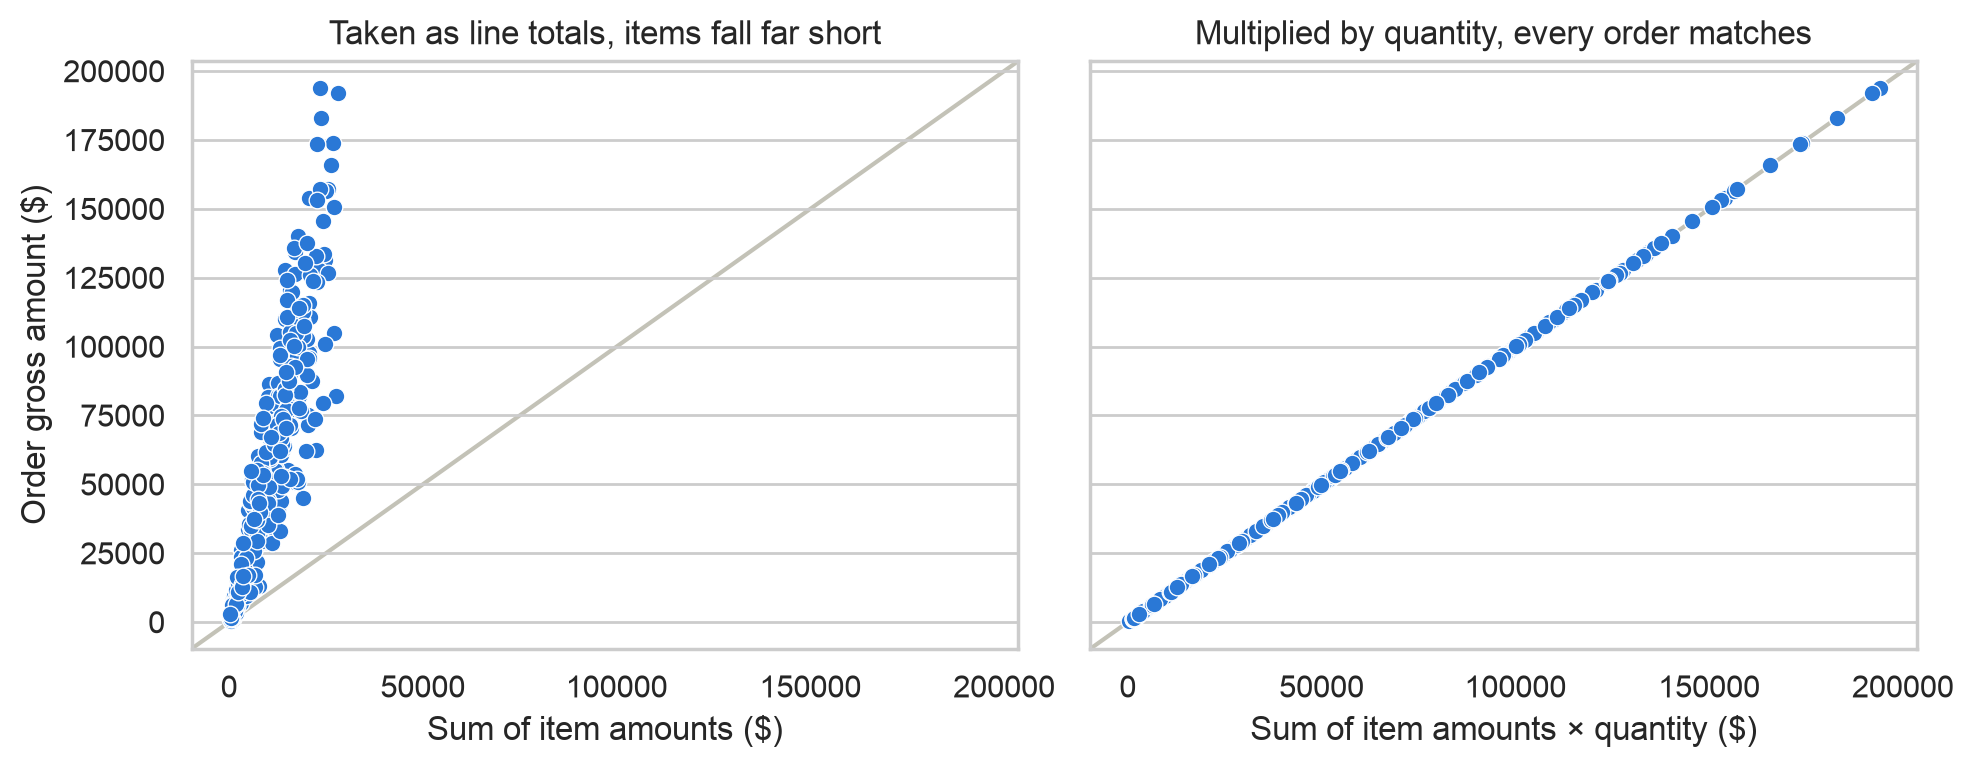

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

sns.scatterplot(data=orders, x="GROSSAMOUNT_stored", y="GROSSAMOUNT", color=BLUE, ax=axes[0])
axes[0].set(title="Taken as line totals, items fall far short", xlabel="Sum of item amounts ($)", ylabel="Order gross amount ($)")

sns.scatterplot(data=orders, x="line_gross", y="GROSSAMOUNT", color=BLUE, ax=axes[1])
axes[1].set(title="Multiplied by quantity, every order matches", xlabel="Sum of item amounts × quantity ($)")

for ax in axes:
    ax.axline((0, 0), slope=1, color=GRAY, zorder=0)
    ax.set_xticks(range(0, 200001, 50000))

plt.tight_layout()
plt.show()

Points on the gray line are orders whose items add up to the order total. Applying quantity puts all 334 orders on it.

In [12]:
rounded_net = (items["NETAMOUNT"].round(2) * items["QUANTITY"]).groupby(items["SALESORDERID"]).sum()
difference = np.abs(orders.set_index("SALESORDERID")["NETAMOUNT"] - rounded_net)

print("Item net amounts that use three decimals:", (items["NETAMOUNT"].round(2) != items["NETAMOUNT"]).sum(), "of", len(items))
print("Orders whose net total breaks if items are rounded to 2 decimals:", (difference >= 0.001).sum(), "of", len(orders))
print(f"Largest difference: ${difference.max():.2f}")

Item net amounts that use three decimals: 1371 of 1930
Orders whose net total breaks if items are rounded to 2 decimals: 322 of 334
Largest difference: $0.22


Rounding to two decimals would break nearly every order total, so amounts must keep three decimals.

## 4. Distributions

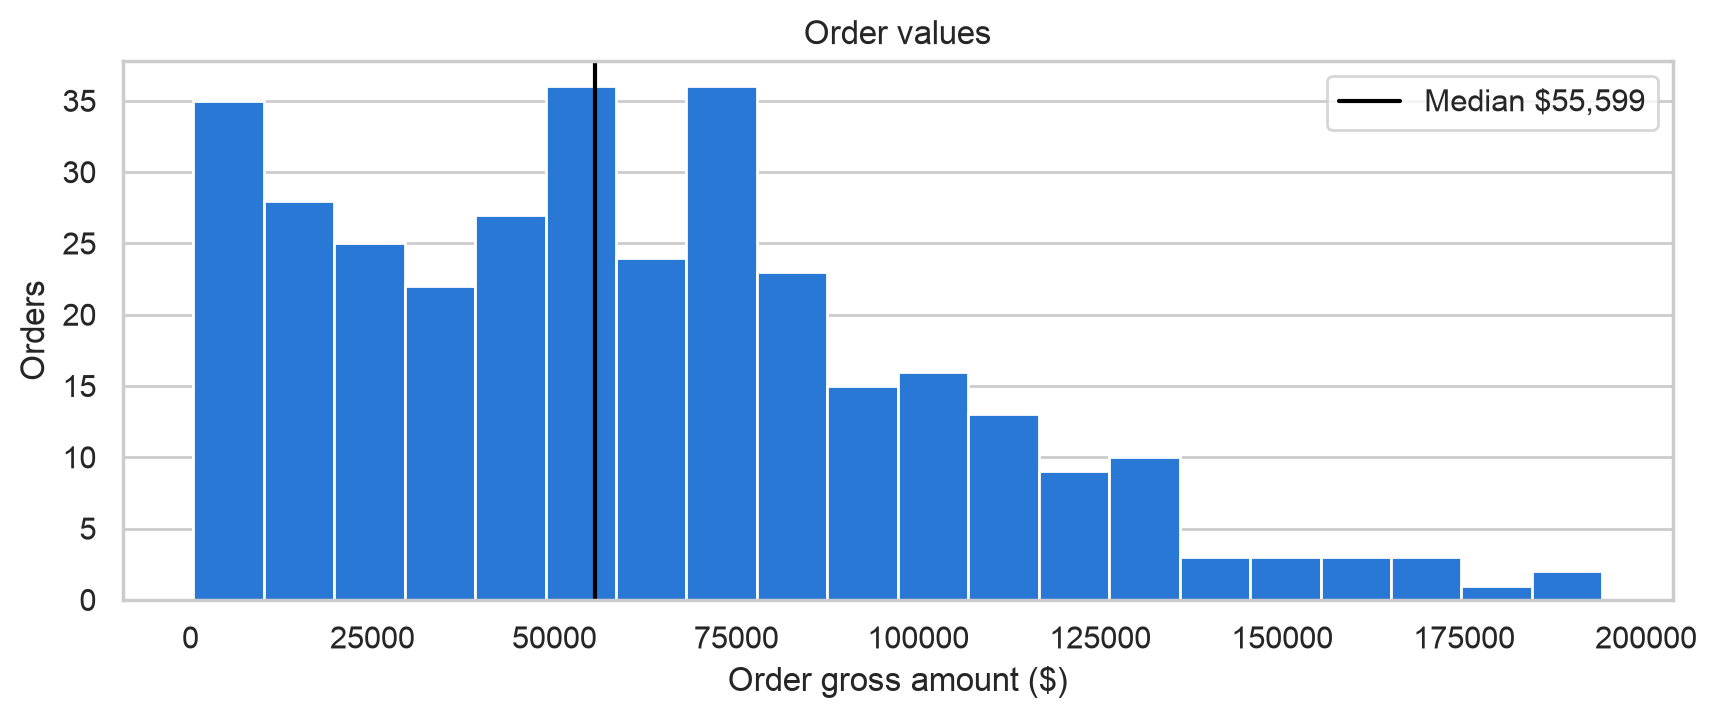

Skewness: 0.66
Orders above the IQR fence: 5 | matching their items: 5


In [13]:
plt.figure(figsize=(10, 3.5))
sns.histplot(orders["GROSSAMOUNT"], bins=20, color=BLUE, alpha=1)
plt.axvline(orders["GROSSAMOUNT"].median(), color="black", label=f"Median ${orders['GROSSAMOUNT'].median():,.0f}")
plt.title("Order values")
plt.xlabel("Order gross amount ($)")
plt.ylabel("Orders")
plt.legend()
plt.show()

q1, q3 = orders["GROSSAMOUNT"].quantile([0.25, 0.75])
large = orders[orders["GROSSAMOUNT"] > q3 + 1.5 * (q3 - q1)]
print("Skewness:", round(orders["GROSSAMOUNT"].skew(), 2))
print("Orders above the IQR fence:", len(large), "| matching their items:", same(large["GROSSAMOUNT"], large["line_gross"]).sum())

Skew is mild, and the 5 unusually large orders all match their items. They are genuine, so no outlier treatment is needed.

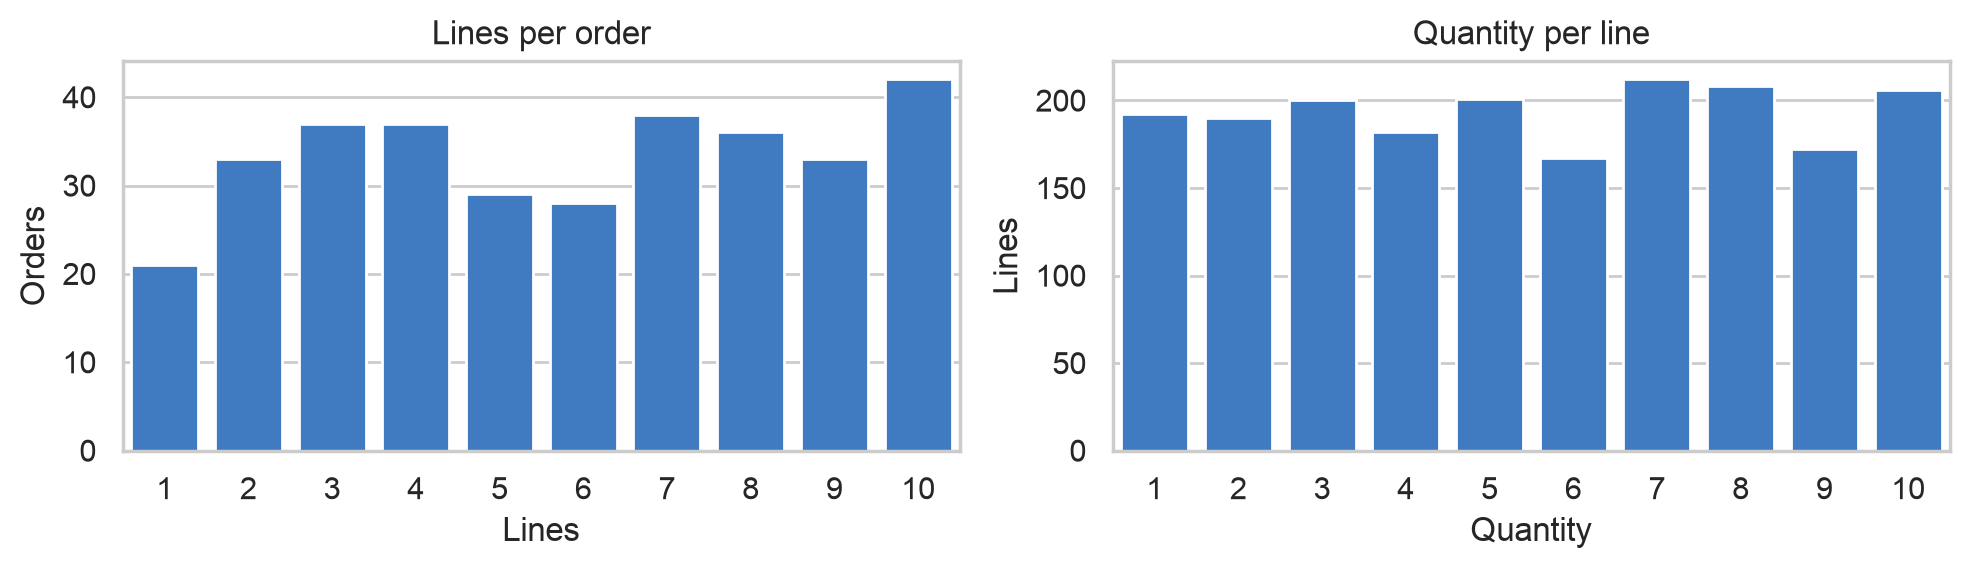

Lines repeating a product already on the same order: 146


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

sns.countplot(x=items.groupby("SALESORDERID").size(), color=BLUE, ax=axes[0])
axes[0].set(title="Lines per order", xlabel="Lines", ylabel="Orders")

sns.countplot(x=items["QUANTITY"], color=BLUE, ax=axes[1])
axes[1].set(title="Quantity per line", xlabel="Quantity", ylabel="Lines")

plt.tight_layout()
plt.show()

print("Lines repeating a product already on the same order:", items.duplicated(["SALESORDERID", "PRODUCTID"]).sum())

Both range from 1 to 10 with no invalid values, and their fairly even spread suggests generated data. Because products repeat
on 146 lines, a product can't identify a line: changes must target the item number.

In [15]:
live_orders = orders[orders["LIFECYCLESTATUS"] != "X"]
live_items = items[items["SALESORDERID"].isin(live_orders["SALESORDERID"])]

products["category"] = products["PRODCATEGORYID"].map(category_texts.set_index("PRODCATEGORYID")["SHORT_DESCR"])
sales = live_items.merge(products[["PRODUCTID", "category"]], on="PRODUCTID").groupby("category")["line_gross"].sum()

category_summary = products.groupby("category")["PRICE"].agg(["count", "min", "max"])
category_summary["sales"] = sales
category_summary["sales_share"] = (sales / sales.sum()).round(3)
category_summary.sort_values("sales", ascending=False)

,count,min,max,sales,sales_share
category,,,,,
eBike,7,1500.0,7900.0,7148350.0,0.354
Racing Bike,7,1999.0,5499.0,6390794.0,0.316
Mountain Bike,4,649.0,3999.0,2162015.0,0.107
Cyclo-cross Bike,3,1144.0,1361.0,1084705.0,0.054
Downhill Bike,3,1199.0,1499.0,1038353.0,0.051
Hybrid Bike,6,379.0,1199.0,971372.0,0.048
BMX,6,249.0,799.0,693076.0,0.034
Road Bike,3,525.0,721.0,423232.0,0.021
Cruiser,3,288.0,400.0,288992.0,0.014


eBikes and Racing Bikes hold 67% of sales, and no list price looks wrong. Category names live in a separate table, so they
should be merged into products.

In [16]:
display(live_orders.groupby("SALESORG")["GROSSAMOUNT"].agg(["count", "sum"]).sort_values("sum", ascending=False))

orders_per_partner = live_orders["PARTNERID"].value_counts()
print("Orders per partner:", orders_per_partner.min(), "to", orders_per_partner.max())

,count,sum
SALESORG,,
EMEA,151,9031740.0
AMER,93,5621735.0
APJ,87,5547414.0


Orders per partner: 3 to 13


EMEA leads with 45% of gross, and orders are spread evenly across partners, so no partner dominates lookups.

## 5. Status and dates

In [17]:
orders.groupby(["LIFECYCLESTATUS", "BILLINGSTATUS", "DELIVERYSTATUS"]).size().sort_values(ascending=False).to_frame("orders")

orders
LIFECYCLESTATUS BILLINGSTATUS DELIVERYSTATUS        
C               C             C                  311
I               I             C                   12
                              I                    7
X               X             X                    3
I               C             I                    1

`C` is completed, `I` in progress and `X` cancelled. Cancelled orders are `X` in all three columns. The 20 in-progress orders are
valid workflow states: 12 delivered but unbilled, 7 neither delivered nor billed, and 1 billed but undelivered.

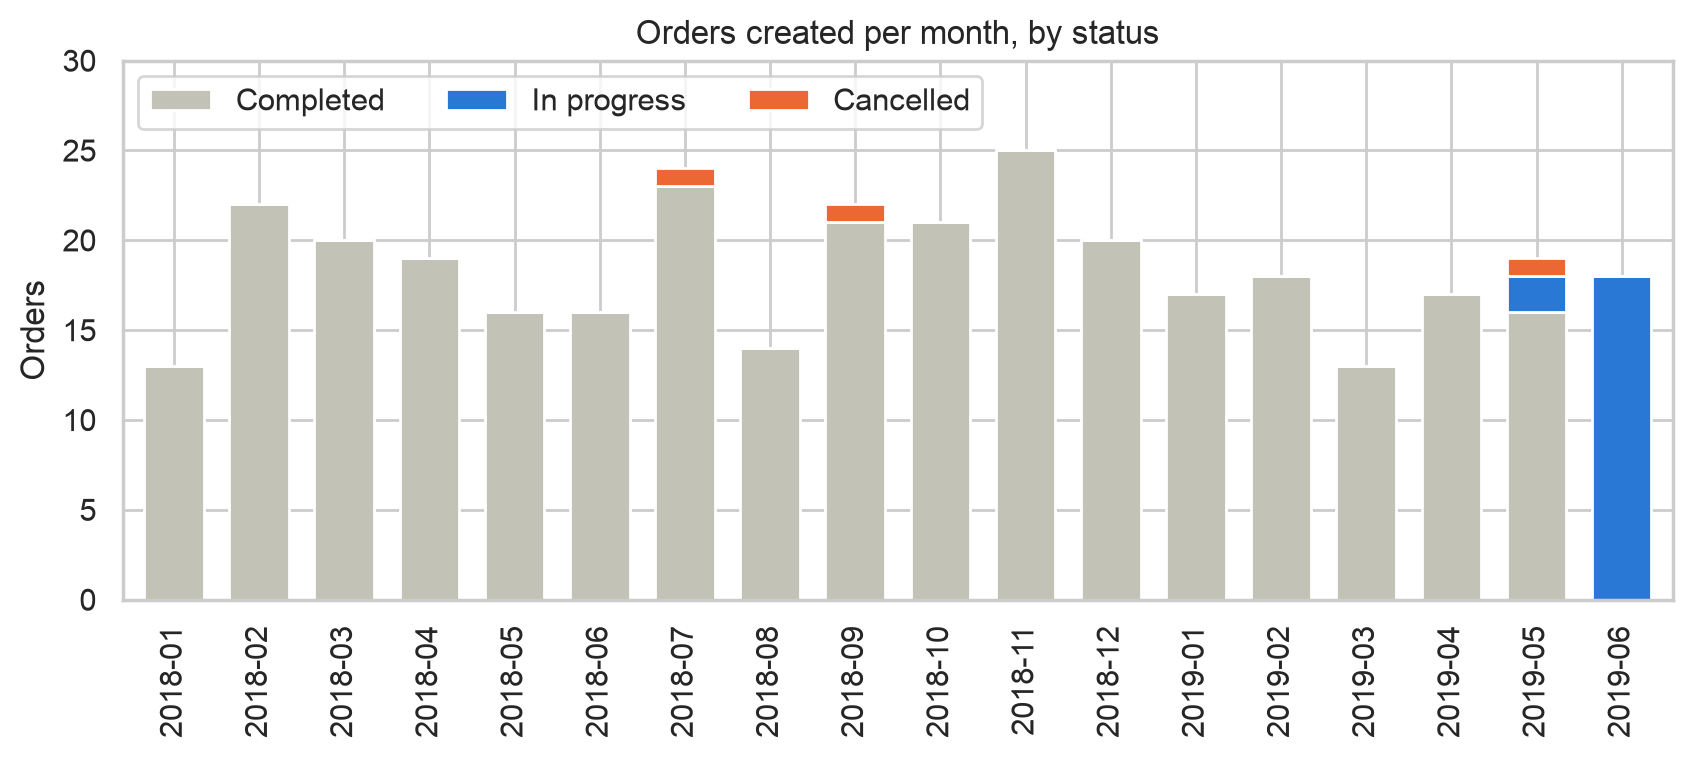

Orders per month: 13 to 25


In [18]:
orders["CREATEDAT"] = pd.to_datetime(orders["CREATEDAT"], format="%Y%m%d")
orders["CHANGEDAT"] = pd.to_datetime(orders["CHANGEDAT"], format="%Y%m%d")

by_month = pd.crosstab(orders["CREATEDAT"].dt.strftime("%Y-%m"), orders["LIFECYCLESTATUS"])[["C", "I", "X"]]
by_month.columns = ["Completed", "In progress", "Cancelled"]

by_month.plot(kind="bar", stacked=True, figsize=(10, 3.5), width=0.7, color=[GRAY, BLUE, ORANGE])
plt.title("Orders created per month, by status")
plt.xlabel("")
plt.ylabel("Orders")
plt.ylim(0, 30)
plt.legend(loc="upper left", ncols=3)
plt.show()

print("Orders per month:", by_month.sum(axis=1).min(), "to", by_month.sum(axis=1).max())

Volume is steady at 13 to 25 orders a month. In-progress orders appear only in May and June 2019, and just 20 of 334 (6%) are
open, which limits what an agent can realistically change.

In [19]:
latest = orders["CHANGEDAT"].max()
master_date = pd.to_datetime(products["CREATEDAT"].iloc[0], format="%Y%m%d")

print("Orders created from", orders["CREATEDAT"].min().date(), "to", orders["CREATEDAT"].max().date())
print("Latest activity:", latest.date(), f"({latest.day_name()})")
print("Partner creation dates:", partners["CREATEDAT"].unique().tolist(), "| product creation dates:", products["CREATEDAT"].unique().tolist())
print("Orders created before that date:", (orders["CREATEDAT"] < master_date).sum())
print("Fiscal period matches the creation month:", (orders["FISCALYEARPERIOD"] == orders["CREATEDAT"].dt.strftime("%Y0%m")).sum(), "of", len(orders))

Orders created from 2018-01-11 to 2019-06-27
Latest activity: 2019-07-01 (Monday)
Partner creation dates: ['20181003'] | product creation dates: ['20181003']
Orders created before that date: 169
Fiscal period matches the creation month: 334 of 334


Activity stops in mid-2019, so questions like "last month" would return nothing unless dates move forward. All partners and
products were "created" after 169 of the orders that use them, so that date must move to before the first order. Fiscal
periods follow the creation month, so they must be recalculated after any shift.

Lines with delivery date 29991212: 22 | statuses of their orders: ['X']
Cancelled orders: 3
Most delivery dates on a single order: 1


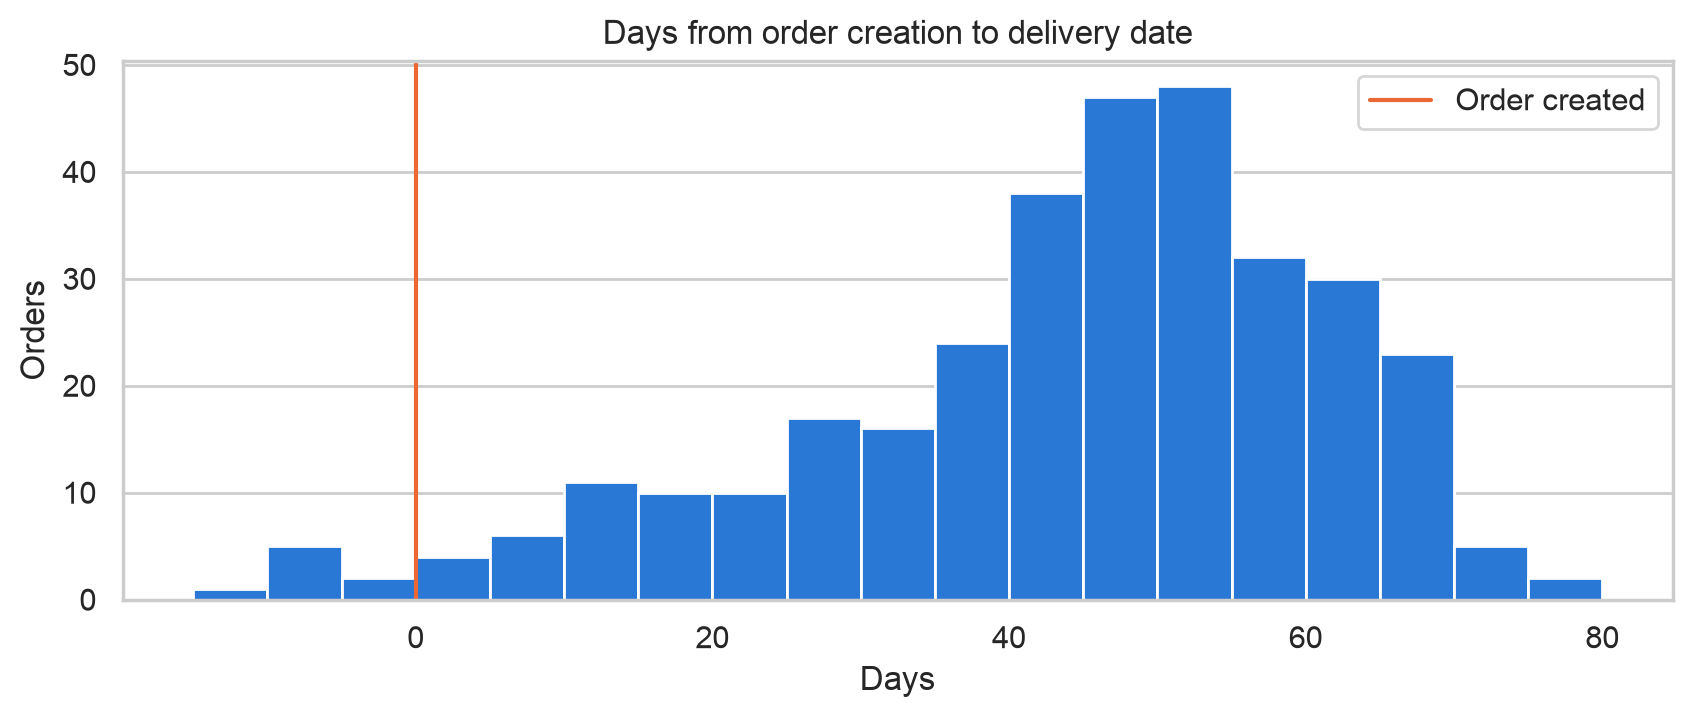

In [20]:
placeholder = items["DELIVERYDATE"] == "29991212"
placeholder_orders = orders[orders["SALESORDERID"].isin(items.loc[placeholder, "SALESORDERID"])]
print("Lines with delivery date 29991212:", placeholder.sum(), "| statuses of their orders:", placeholder_orders["LIFECYCLESTATUS"].unique().tolist())
print("Cancelled orders:", (orders["LIFECYCLESTATUS"] == "X").sum())
print("Most delivery dates on a single order:", items.groupby("SALESORDERID")["DELIVERYDATE"].nunique().max())

deliveries = items.loc[~placeholder, ["SALESORDERID", "DELIVERYDATE"]].drop_duplicates()
deliveries["DELIVERYDATE"] = pd.to_datetime(deliveries["DELIVERYDATE"], format="%Y%m%d")
deliveries = deliveries.merge(orders[["SALESORDERID", "CREATEDAT", "CHANGEDAT", "BILLINGSTATUS", "DELIVERYSTATUS"]], on="SALESORDERID")
deliveries["lag_days"] = (deliveries["DELIVERYDATE"] - deliveries["CREATEDAT"]).dt.days

plt.figure(figsize=(10, 3.5))
sns.histplot(deliveries["lag_days"], bins=np.arange(-15, 85, 5), color=BLUE, alpha=1)
plt.axvline(0, color=ORANGE, label="Order created")
plt.title("Days from order creation to delivery date")
plt.xlabel("Days")
plt.ylabel("Orders")
plt.legend()
plt.show()

`29991212` marks exactly the 3 cancelled orders and means "no delivery", so it should become a blank. Every order has one delivery
date, but some fall left of the orange line, before the order existed.

In [21]:
early = deliveries[deliveries["lag_days"] < 0]
undelivered = deliveries[deliveries["DELIVERYSTATUS"] == "I"]

display(early)
print("Lines on those orders:", items["SALESORDERID"].isin(early["SALESORDERID"]).sum())
print("Undelivered orders:", len(undelivered), "| already past their delivery date:", (undelivered["DELIVERYDATE"] <= latest).sum())

,SALESORDERID,DELIVERYDATE,CREATEDAT,CHANGEDAT,BILLINGSTATUS,DELIVERYSTATUS,lag_days
318,0500000321,2019-06-05,2019-06-12,2019-06-15,I,C,-7
320,0500000323,2019-06-10,2019-06-15,2019-06-17,I,C,-5
321,0500000324,2019-06-06,2019-06-16,2019-06-17,I,C,-10
322,0500000325,2019-06-14,2019-06-17,2019-06-21,I,C,-3
323,0500000326,2019-06-06,2019-06-17,2019-06-18,I,C,-11
326,0500000329,2019-06-13,2019-06-19,2019-06-20,I,C,-6
327,0500000330,2019-06-13,2019-06-22,2019-06-26,I,C,-9
329,0500000332,2019-06-19,2019-06-27,2019-07-01,I,C,-8


Lines on those orders: 52
Undelivered orders: 8 | already past their delivery date: 6


Eight delivered-but-unbilled orders have impossible dates, up to 11 days before creation. Their last-change date falls after
creation, so it's a safe replacement. The 6 overdue orders are a useful natural case worth keeping.

## 6. Partners, products and employees

In [22]:
partner_addresses = partners.merge(addresses, on="ADDRESSID")
display(partner_addresses.groupby(["COUNTRY", "REGION", "CURRENCY"]).size().to_frame("partners"))

order_partners = orders.merge(partner_addresses[["PARTNERID", "REGION", "CURRENCY"]], on="PARTNERID", suffixes=("", "_PARTNER"))
print("Cities with country code DU:", addresses.loc[addresses["COUNTRY"] == "DU", "CITY"].unique().tolist())
print("Partners per address, at most:", partners["ADDRESSID"].value_counts().max())
print("Orders whose sales org equals the partner's region:", (order_partners["SALESORG"] == order_partners["REGION"]).sum(), "of", len(orders))
print("Orders in a currency other than the partner's own:", (order_partners["CURRENCY"] != order_partners["CURRENCY_PARTNER"]).sum(), "of", len(orders))

,,,partners
COUNTRY,REGION,CURRENCY,
AU,APJ,AUD,5
CA,AMER,CAD,5
DE,EMEA,EUR,5
DU,EMEA,AED,5
FR,EMEA,EUR,5
GB,EMEA,GBP,5
IN,APJ,INR,5
US,AMER,USD,5


Cities with country code DU: ['Jebel Ali Free Zone', 'Dubai']
Partners per address, at most: 1
Orders whose sales org equals the partner's region: 334 of 334
Orders in a currency other than the partner's own: 286 of 334


`DU` isn't a valid country code: these are Dubai addresses, so it should be `AE`. Each partner has one address, so addresses can
merge into partners. Most orders aren't in the partner's own currency, so that currency is only a preference and nothing should
be converted.

In [23]:
english = product_texts[product_texts["LANGUAGE"] == "EN"]
print("Text rows by language:", product_texts["LANGUAGE"].value_counts().to_dict())
print("Products with an English text:", english["PRODUCTID"].nunique(), "of", len(products))
print("Unique English short names:", english["SHORT_DESCR"].nunique(), "| blank medium names:", (english["MEDIUM_DESCR"] == "").sum())

Text rows by language: {'EN': 42, 'DE': 2}
Products with an English text: 42 of 42
Unique English short names: 42 | blank medium names: 8


English text covers every product with a unique name, so product texts can merge into products and the two German rows can go.

In [24]:
employee_region = employees.merge(addresses, on="ADDRESSID").set_index("EMPLOYEEID")["REGION"]
print("Orders whose sales org equals their creator's region:", (orders["CREATEDBY"].map(employee_region) == orders["SALESORG"]).sum(), "of", len(orders))

pd.crosstab(orders["CREATEDBY"], orders["SALESORG"])

Orders whose sales org equals their creator's region: 334 of 334


SALESORG,AMER,APJ,EMEA
CREATEDBY,,,
0000000001,17,0,0
0000000002,0,0,44
0000000003,0,0,32
0000000004,0,49,0
0000000005,0,39,0
0000000006,0,0,30
0000000007,7,0,0
0000000008,0,0,45
0000000009,16,0,0


Every employee sells in exactly one org, which always matches their address region. Sales org can safely be added to employees.

## 7. What preprocessing must do

The data is structurally sound, with no duplicates, nothing to impute and no outliers to remove.

| Finding | Action |
|---|---|
| Item amounts are per unit | Rename as unit amounts and add line totals |
| Rounding to two decimals breaks order totals | Keep three decimals |
| 8 orders delivered before creation (52 lines) | Use the order's last-change date as the delivery date |
| `29991212` on the 3 cancelled orders (22 lines) | Store as blank |
| Partners and products dated after 169 orders | Move to before the first order |
| Activity stops on Monday 2019-07-01 | Shift all dates 2,681 days, to Monday 2026-11-02, and recalculate fiscal periods |
| 2 suppliers don't exist | Leave the supplier blank |
| `DU` is an invalid country code | Change to `AE` |
| Stray spaces and non-breaking spaces | Clean the text, and remove whitespace from logins |
| Mixed encodings, blank columns, leading zeros | Read as text per file, and write everything as UTF-8 |
| Empty and constant columns, `PARTNERROLE` | Drop, keeping currency, units and audit dates |
| Addresses, product texts and categories in separate tables | Merge into partners and products, in English |
| Each employee works in one region | Add sales org to employees |

**Leave as is:** repeated products on an order, partner currencies, large orders, blank buildings and middle initials.

**Beyond cleaning:** only 6% of orders are open and the data has no stock levels. Fixing either would mean adding data that isn't
in the source.